In [1]:
import pandas as pd
import numpy as np

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df_main = pd.read_csv(url)
df_main.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df_main.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = list(df_main.select_dtypes(include=["object", "category", "string"]).columns)
numerical = list(df_main.select_dtypes(include="number").columns)
del numerical[-1]

# Handle missing values
df_main[categorical] = df_main[categorical].fillna("NA")
df_main[numerical] = df_main[numerical].fillna(0)

In [5]:
df_main.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [6]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df_main, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train["converted"]
y_test = df_test["converted"]
y_val = df_val["converted"]

del df_train["converted"]
del df_test["converted"]
del df_val["converted"]

df_train.reset_index(inplace=True, drop=True)
df_test.reset_index(inplace=True, drop=True)
df_val.reset_index(inplace=True, drop=True)

In [7]:
from sklearn.metrics import roc_auc_score

In [8]:
for feature in numerical:
    score = roc_auc_score(y_train, df_train[feature])
    print(feature, score) 

annual_income 0.6024181142581669
number_of_courses_viewed 0.7198935273205248
interaction_count 0.7667441243222455
lead_score 0.7878714220972788


In [10]:
from sklearn.feature_extraction import DictVectorizer

dict_train = df_train.to_dict(orient='records')
dict_test = df_test.to_dict(orient='records')
dict_val = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dict_train)
X_test = dv.transform(dict_test)
X_val = dv.transform(dict_val)


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:,-1]
round(roc_auc_score(y_val, y_pred), 3)

0.729

In [15]:
thresholds = np.linspace(0, 1, 101)
list_precision = []
list_recal = []

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    # p = tp / (tp + fp)
    # r = tp / (tp + fn)

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    list_precision.append(p)
    list_recal.append(r)

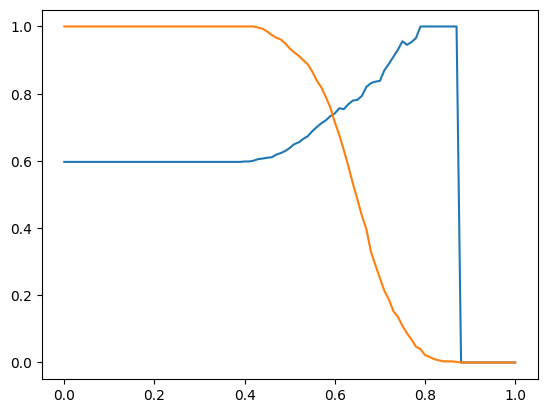

In [16]:
import matplotlib.pyplot as plt 

plt.plot(thresholds, list_precision)
plt.plot(thresholds, list_recal) 

In [17]:
matching_indices = [
    i for i, (a, b) in enumerate(zip(list_precision, list_recal))
    if a == b
]

In [18]:
matching_indices

[88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]

In [19]:
f1_list = []

for p, r in zip(list_precision, list_recal): 
    f1 = 2 * p * r / (p + r) if (p + r) > 0  else 0
    f1_list.append(f1)

In [20]:
best_index = np.argmax(f1_list)

best_threshold = thresholds[best_index]
best_f1 = f1_list[best_index]

print("Best threshold:", best_threshold)
print("Best F1 score:", best_f1)

Best threshold: 0.55
Best F1 score: 0.7670623145400592


In [22]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

C = [0.000001, 0.001, 1]

for c in C:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        X_train = df_full_train.iloc[train_idx]
        y_train = df_full_train.iloc[train_idx]["converted"]

        X_val = df_full_train.iloc[val_idx]
        y_val = df_full_train.iloc[val_idx]["converted"]

        del X_train["converted"]
        del X_val["converted"]

        X_train = X_train.to_dict(orient='records')
        X_val = X_val.to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(X_train)
        X_val = dv.transform(X_val)

        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:,-1]
        score = roc_auc_score(y_val, y_pred)
        scores.append(score)
    print(c, np.mean(score), np.std(scores))

1e-06 0.613125275117862 0.010442094537492959
0.001 0.7318868779146545 0.013162676233145714
1 0.7206716384584467 0.01166690694261335
